# TRAITEMENT DE DONNÉES

## 1. Importation des bibliothèques

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error,mean_squared_error

## 2. Importation et aperçu des données

In [17]:
data=pd.read_excel("Data//Qj_Bonou.xlsx")
data_comp=pd.read_excel("Data//Qj-Bonou-Complement.xlsx")
data.index=range(len(data))
data_comp.index=range(len(data_comp))

data.head()

,Date,1992,1993,1994,1995,1996,1997,1998,1999,2000,...,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022
0,1904-01-01 12:00:00,17.280001,12.00,10.210,NaN,26.020000,12.83,13.49,20.389999,23.120001,...,258.899994,8.858,8.824,23.120001,13.21,11.09,25.490000,4.584,4.23,0.634
1,1904-01-02 12:00:00,17.280001,12.00,9.906,NaN,25.340000,12.58,13.33,20.100000,22.760000,...,257.899994,8.680,8.826,22.760000,13.39,11.08,25.320000,4.111,4.23,0.636
2,1904-01-03 12:00:00,17.150000,12.00,9.796,NaN,24.660000,12.33,13.06,19.799999,22.180000,...,256.799988,8.630,9.243,22.180000,13.52,10.80,25.160000,3.606,4.23,0.637
3,1904-01-04 12:00:00,17.000000,11.89,9.789,NaN,24.100000,12.08,12.72,19.510000,21.590000,...,255.800003,8.477,9.133,21.590000,13.27,10.67,24.059999,3.330,4.23,0.635
4,1904-01-05 12:00:00,16.889999,11.66,9.440,NaN,23.540001,11.83,12.58,19.219999,20.990000,...,254.699997,8.427,8.888,20.990000,12.94,10.50,22.170000,3.145,4.23,0.636


In [18]:
data_comp.head()

,Date,2021,2022,2023
0,1904-01-01 12:00:00,4.23,0.634,0.718
1,1904-01-02 12:00:00,4.23,0.636,0.735
2,1904-01-03 12:00:00,4.23,0.637,0.728
3,1904-01-04 12:00:00,4.23,0.635,0.723
4,1904-01-05 12:00:00,4.23,0.636,0.714


### 2.1 Vérification de la complémentarité entre les deux jeux de données

In [19]:
print(f"{(data["Date"]!=data_comp['Date']).sum()} valeur différent dans la colonne Date\n")
print(f"{(data["2021"]!=data_comp['2021']).sum()} valeur différent dans la colonne 2021\n")
print(f"{data[data["2022"]!=data_comp['2022']]["2022"]} valeur différent dans la colonne 2022 qui sont\n {data[data["2022"]!=data_comp["2022"]].index}")

0 valeur différent dans la colonne Date

0 valeur différent dans la colonne 2021

186   NaN
187   NaN
188   NaN
189   NaN
190   NaN
       ..
361   NaN
362   NaN
363   NaN
364   NaN
365   NaN
Name: 2022, Length: 180, dtype: float64 valeur différent dans la colonne 2022 qui sont
 RangeIndex(start=186, stop=366, step=1)


### 2.2 Concaténation des deux jeux de données

In [20]:
data_gen=pd.concat([data,data_comp.drop(["2021","2022","Date"],axis=1)],axis=1)
data_gen["2022"]=data_comp["2022"]
data_gen.head()

,Date,1992,1993,1994,1995,1996,1997,1998,1999,2000,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
0,1904-01-01 12:00:00,17.280001,12.00,10.210,NaN,26.020000,12.83,13.49,20.389999,23.120001,...,8.858,8.824,23.120001,13.21,11.09,25.490000,4.584,4.23,0.634,0.718
1,1904-01-02 12:00:00,17.280001,12.00,9.906,NaN,25.340000,12.58,13.33,20.100000,22.760000,...,8.680,8.826,22.760000,13.39,11.08,25.320000,4.111,4.23,0.636,0.735
2,1904-01-03 12:00:00,17.150000,12.00,9.796,NaN,24.660000,12.33,13.06,19.799999,22.180000,...,8.630,9.243,22.180000,13.52,10.80,25.160000,3.606,4.23,0.637,0.728
3,1904-01-04 12:00:00,17.000000,11.89,9.789,NaN,24.100000,12.08,12.72,19.510000,21.590000,...,8.477,9.133,21.590000,13.27,10.67,24.059999,3.330,4.23,0.635,0.723
4,1904-01-05 12:00:00,16.889999,11.66,9.440,NaN,23.540001,11.83,12.58,19.219999,20.990000,...,8.427,8.888,20.990000,12.94,10.50,22.170000,3.145,4.23,0.636,0.714


### 2.3 Informations générales sur les données

In [21]:
data_gen.info()

<class 'pandas.DataFrame'>
RangeIndex: 366 entries, 0 to 365
Data columns (total 33 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    366 non-null    datetime64[us]
 1   1992    366 non-null    float64       
 2   1993    366 non-null    float64       
 3   1994    365 non-null    float64       
 4   1995    306 non-null    float64       
 5   1996    334 non-null    float64       
 6   1997    366 non-null    float64       
 7   1998    366 non-null    float64       
 8   1999    366 non-null    float64       
 9   2000    366 non-null    float64       
 10  2001    366 non-null    float64       
 11  2002    366 non-null    float64       
 12  2003    366 non-null    float64       
 13  2004    366 non-null    float64       
 14  2005    366 non-null    float64       
 15  2006    0 non-null      float64       
 16  2007    366 non-null    float64       
 17  2008    366 non-null    float64       
 18  2009    0 non-null   

## 3. Création du jeu de données de travail

In [22]:
df_final=pd.DataFrame()
df_final["Date"]=pd.date_range(start="1992-01-01",end="2023-12-31",freq="D")
data_gen["jour"]=data_gen["Date"].dt.day
data_gen["mois"]=data_gen["Date"].dt.month
def fonc(x):
    return data_gen[(data_gen.jour==x.day) & (data_gen.mois==x.month)][f"{x.year}"].iloc[0]

df_final["Valeur"]=df_final["Date"].apply(fonc)
df_final=df_final[~((df_final.Date.dt.month == 2) & (df_final.Date.dt.day == 29))]
df_final.head()

,Date,Valeur
0,1992-01-01,17.280001
1,1992-01-02,17.280001
2,1992-01-03,17.150000
3,1992-01-04,17.000000
4,1992-01-05,16.889999


## 4. Traitement des valeurs manquantes
### 4.1 Pourcentage de valeurs manquantes par année

In [23]:
def bilan(donnee):
    bilan=donnee.groupby(donnee.Date.dt.year)["Valeur"].agg(total="size",manquante=lambda x:x.isnull().sum())
    bilan["Pourcentage valeur manquante"]=bilan["manquante"]*100/bilan["total"]
    return bilan

df_final.to_excel("Data//donne_avec_manquante.xlsx")
bilan(df_final) 

,total,manquante,Pourcentage valeur manquante
Date,,,
1992,365,0,0.000000
1993,365,0,0.000000
1994,365,1,0.273973
1995,365,59,16.164384
1996,365,32,8.767123
1997,365,0,0.000000
1998,365,0,0.000000
1999,365,0,0.000000
2000,365,0,0.000000


### 4.2 Imputation des séquences courtes (1 à 3 jours) — Interpolation linéaire

In [24]:
def interpolation_max_3(df):
    result = df.copy()

    for col in result.columns:
        s = result[col]

        # Identifier les groupes de valeurs manquantes
        groupe = s.notna().cumsum()
        tailles = s.isna().groupby(groupe).transform("sum")

        # Interpolation temporaire
        interp = s.interpolate(method="linear")

        # On ne conserve l'interpolation que pour les groupes <= 3
        mask = s.isna() & (tailles <= 3)

        result.loc[mask, col] = interp.loc[mask]

    return result

df_final = interpolation_max_3(df_final)
df_final.to_excel("Data//donne_avec_manquante.xlsx")

bilan(df_final)

,total,manquante,Pourcentage valeur manquante
Date,,,
1992,365,0,0.000000
1993,365,0,0.000000
1994,365,1,0.273973
1995,365,59,16.164384
1996,365,32,8.767123
1997,365,0,0.000000
1998,365,0,0.000000
1999,365,0,0.000000
2000,365,0,0.000000


# Methode d'imputation avec la méthode interannuelle sur 2007 

In [25]:
val_vrai=pd.DataFrame(df_final[df_final.Date.dt.year==2010]["Valeur"].values,columns=["valeur"])

donnee=df_final[df_final.Date.dt.year==2010]
donnee["Valeur"]=np.nan
def impu(x):
    index=((df_final.Date.dt.month==x.month) & (df_final.Date.dt.day==x.day))

    return df_final.loc[index,"Valeur"].mean()

donnee["Valeur"]=donnee["Date"].apply(impu)

donnee["Valeur"].values


array([ 21.65386194,  21.47075844,  21.27358574,  21.01706907,
        20.7182757 ,  20.44017272,  20.20141392,  19.98737921,
        19.8171379 ,  19.65272391,  19.48331045,  19.33368968,
        19.16182751,  19.00068942,  18.81924148,  18.69106904,
        18.49841374,  18.3147238 ,  18.18624113,  18.06589662,
        17.94172413,  17.8221722 ,  17.69068974,  17.59403467,
        17.12572412,  16.98958618,  16.91013779,  16.98217251,
        16.91451729,  16.84910331,  16.79420674,  16.73175881,
        16.70358614,  16.68896551,  16.62806875,  16.52186184,
        16.4043449 ,  16.29444816,  16.21462056,  16.09251745,
        16.01665534,  15.91144824,  15.76396537,  15.67227568,
        15.61772424,  15.56024151,  15.5171378 ,  15.44110361,
        15.37434493,  15.4547241 ,  15.3979655 ,  15.25162046,
        15.13775872,  15.1316898 ,  15.10689643,  15.03906885,
        14.91831049,  14.8284485 ,  14.75055168,  14.4735331 ,
        14.46229976,  14.52430003,  14.60933333,  14.55

MAE : 91.08361931855777
RMSE : 147.34027179385512


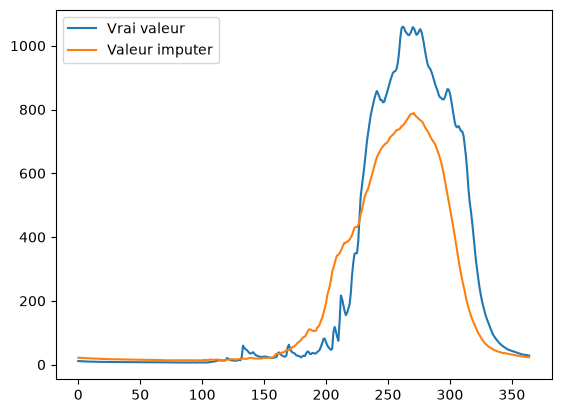

In [26]:
print(f"MAE : {mean_absolute_error(val_vrai,donnee["Valeur"].values)}")
print(f"RMSE : {np.sqrt(mean_squared_error(val_vrai,donnee["Valeur"].values))}")

plt.plot(range(len(val_vrai)), val_vrai, label="Vrai valeur")
plt.plot(range(len(val_vrai)), donnee["Valeur"].values, label="Valeur imputer")

plt.legend()


### 4.3 Imputation des longues lacunes — Moyenne journalière interannuelle

In [27]:
def impu(x):
    index=((df_final.Date.dt.month==x.month) & (df_final.Date.dt.day==x.day))

    return df_final.loc[index,"Valeur"].mean()

idx_mar=df_final.Valeur.isnull()

df_final.loc[idx_mar,"Valeur"]=df_final.loc[idx_mar,"Date"].apply(impu)

bilan(df_final)

,total,manquante,Pourcentage valeur manquante
Date,,,
1992,365,0,0.0
1993,365,0,0.0
1994,365,0,0.0
1995,365,0,0.0
1996,365,0,0.0
1997,365,0,0.0
1998,365,0,0.0
1999,365,0,0.0
2000,365,0,0.0


## 5. Vérification des valeurs négatives

In [28]:
df_final[df_final.Valeur<0]

,Date,Valeur


In [29]:
df_final.shape

(11680, 2)

## 6. Sauvegarde du jeu de données final

In [30]:
df_final.to_excel("Data//donnee_debit_trait.xlsx",index=False)